# Activity: Build a K-means model

## **Introduction**

K-means clustering is very effective when segmenting data and attempting to find patterns. Because clustering is used in a broad array of industries, becoming proficient in this process will help you expand your skillset in a widely applicable way.   

In this activity, you are a consultant for a scientific organization that works to support and sustain penguin colonies. You are tasked with helping other staff members learn more about penguins in order to achieve this mission.

The data for this activity is in a spreadsheet that includes datapoints across a sample size of 345 penguins, such as species, island, and sex. Your will use a K-means clustering model to group this data and identify patterns that provide important insights about penguins.

**Note:** Because this lab uses a real dataset, this notebook will first require basic EDA, data cleaning, and other manipulations to prepare the data for modeling.

## **Step 1: Imports**


Import statements including `K-means`, `silhouette_score`, and `StandardScaler`.

In [176]:
# Import standard operational packages.

# Important tools for modeling and evaluation.(scikit.learna and so on  )

# Import standard operational packages.
import pandas as pd
import numpy as np

# Important tools for modeling and evaluation.
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler




In [177]:
# Import visualization packages.

### YOUR CODE HERE ###

# Import visualization packages.
import matplotlib.pyplot as plt
import seaborn as sns


`Pandas` is used to load the penguins dataset, which is built into the `seaborn` library. The resulting `pandas` DataFrame is saved in a variable named `penguins`. As shown in this cell, the dataset has been automatically loaded in for you. You do not need to download the .csv file, or provide more code, in order to access the dataset and proceed with this lab. Please continue with this activity by completing the following instructions.

In [178]:
# RUN THIS CELL TO IMPORT YOUR DATA.

# Save the `pandas` DataFrame in variable `penguins`.

### YOUR CODE HERE ###

# RUN THIS CELL TO IMPORT YOUR DATA.

# Save the `pandas` DataFrame in variable `penguins`.

### YOUR CODE HERE ###

url = "https://raw.githubusercontent.com/dyyland23-glitch/k-means/main/penguins.csv"

penguins = pd.read_csv(url)






Now, review the first 10 rows of data.


In [179]:
# Review the first 10 rows.

penguins.head(10)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,female
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,male
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN


## **Step 2: Data exploration**

After loading the dataset, the next step is to prepare the data to be suitable for clustering. This includes:

*   Exploring data
*   Checking for missing values
*   Encoding data
*   Dropping a column
*   Scaling the features using `StandardScaler`

### Explore data

To cluster penguins of multiple different species, determine how many different types of penguin species are in the dataset.

In [180]:
# Find out how many penguin types there are.
penguins['species'].unique()



array(['Adelie', 'Chinstrap', 'Gentoo'], dtype=object)

In [181]:
# Count how many unique penguin species there are
penguins['species'].nunique()




3

**Question:** How many types of species are present in the dataset?

**Question:** Why is it helpful to determine the perfect number of clusters using K-means when you already know how many penguin species the dataset contains?

### Check for missing values

An assumption of K-means is that there are no missing values. Check for missing values in the rows of the data.

In [182]:
# Check for missing values.

### YOUR CODE HERE ###

penguins.isna().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


Now, drop the rows with missing values and save the resulting pandas DataFrame in a variable named `penguins_subset`.

In [183]:


# Drop rows with missing values.
# Save DataFrame in variable `penguins_subset`.

penguins_subset = penguins.dropna(axis=0).reset_index(drop=True)





Next, check to make sure that `penguins_subset` does not contain any missing values.

In [184]:
# Check for missing values.



penguins_subset.isna().sum()



,0
species,0
island,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,0


Now, review the first 10 rows of the subset.

In [185]:
# View first 10 rows.

penguins_subset.head(10)




,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male
5,Adelie,Torgersen,38.9,17.8,181.0,3625.0,female
6,Adelie,Torgersen,39.2,19.6,195.0,4675.0,male
7,Adelie,Torgersen,41.1,17.6,182.0,3200.0,female
8,Adelie,Torgersen,38.6,21.2,191.0,3800.0,male
9,Adelie,Torgersen,34.6,21.1,198.0,4400.0,male


### Encode data

Some versions of the penguins dataset have values encoded in the sex column as 'Male' and 'Female' instead of 'MALE' and 'FEMALE'. The code below will make sure all values are ALL CAPS.


In [186]:
penguins_subset['sex'] = penguins_subset['sex'].str.upper()

K-means needs numeric columns for clustering. Convert the categorical column `'sex'` into numeric. There is no need to convert the `'species'` column because it isn't being used as a feature in the clustering algorithm.

In [187]:


# Convert `sex` column from categorical to numeric.
penguins_subset = pd.get_dummies(penguins_subset, columns=['sex'], drop_first=True)


### Drop a column

Drop the categorical column `island` from the dataset. While it has value, this notebook is trying to confirm if penguins of the same species exhibit different physical characteristics based on sex. This doesn't include location.

Note that the `'species'` column is not numeric. Don't drop the `'species'` column for now. It could potentially be used to help understand the clusters later.

In [188]:

penguins_subset = penguins_subset.drop(columns=["island"])





In [189]:
# Exclude `species` variable from X

# Exclude `species` variable from X
X = penguins_subset.drop(columns=['species'])


### Scale the features

Because K-means uses distance between observations as its measure of similarity, it's important to scale the data before modeling. Use a third-party tool, such as scikit-learn's `StandardScaler` function. `StandardScaler` scales each point xᵢ by subtracting the mean observed value for that feature and dividing by the standard deviation:

x-scaled = (xᵢ – mean(X)) / σ

This ensures that all variables have a mean of 0 and variance/standard deviation of 1.

**Note:** Because the species column isn't a feature, it doesn't need to be scaled.

First, copy all the features except the `'species'` column to a DataFrame `X`.

In [190]:
# Convert `sex` column from categorical to numeric.
# Scale the features.
# Assign the scaled data to variable `X_scaled`.

X_scaled = StandardScaler().fit_transform(X)



Scale the features in `X` using `StandardScaler`, and assign the scaled data to a new variable `X_scaled`.

In [191]:
#Scale the features.
#Assign the scaled data to variable `X_scaled`.

### YOUR CODE HERE ###

#Scale the features.
#Assign the scaled data to variable `X_scaled`.

X_scaled = StandardScaler().fit_transform(X)




## **Step 3: Data modeling**

Now, fit K-means and evaluate inertia for different values of k. Because you may not know how many clusters exist in the data, start by fitting K-means and examining the inertia values for different values of k. To do this, write a function called `kmeans_inertia` that takes in `num_clusters` and `x_vals` (`X_scaled`) and returns a list of each k-value's inertia.

When using K-means inside the function, set the `random_state` to `42`. This way, others can reproduce your results.

In [192]:
# Fit K-means and evaluate inertia for different values of k.

# Fit K-means and evaluate inertia for different values of k.

def kmeans_inertia(num_clusters, x_vals):
    inertia = []
    for k in num_clusters:
        # Fit K-means with the specified number of clusters and random_state=42
        model = KMeans(n_clusters=k, random_state=42, n_init='auto')
        model.fit(x_vals)
        # Append the inertia to the list
        inertia.append(model.inertia_)
    return inertia



Use the `kmeans_inertia` function to return a list of inertia for k=2 to 10.

In [193]:
# Return a list of inertia for k=2 to 10.



# Return a list of inertia for k=2 to 10.
num_clusters = [i for i in range(2, 11)]
inertia = kmeans_inertia(num_clusters, X_scaled)
inertia


[885.6224143652253,
 578.8284278107237,
 477.2295673528196,
 284.5464837898291,
 218.05156297830223,
 201.51585567445807,
 196.58908645819528,
 180.65751845628574,
 170.157035897555]

Next, create a line plot that shows the relationship between `num_clusters` and `inertia`.
Use either seaborn or matplotlib to visualize this relationship.

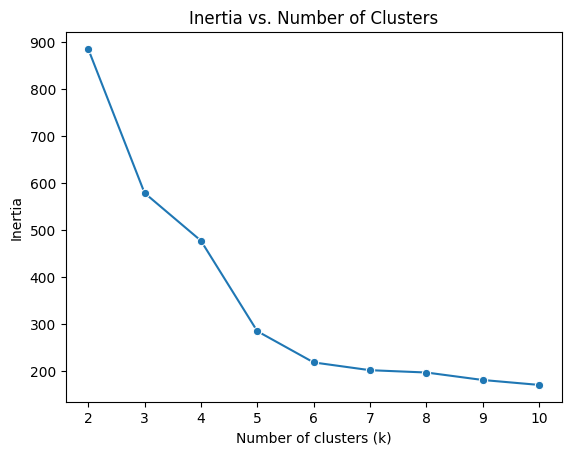

In [194]:
# Create a line plot.

# Create a line plot.
sns.lineplot(x=num_clusters, y=inertia, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Inertia vs. Number of Clusters")
plt.show()




**Question:** Where is the elbow in the plot?

## **Step 4: Results and evaluation**

Now, evaluate the silhouette score using the `silhouette_score()` function. Silhouette scores are used to study the distance between clusters.

Then, compare the silhouette score of each value of k, from 2 through 10. To do this, write a function called `kmeans_sil` that takes in `num_clusters` and `x_vals` (`X_scaled`) and returns a list of each k-value's silhouette score.

In [195]:
# Evaluate silhouette score.
# Write a function to return a list of each k-value's score.

# Evaluate silhouette score.
# Write a function to return a list of each k-value's score.

def kmeans_sil(num_clusters, x_vals):
    sil_scores = []
    for k in num_clusters:
        # Fit K-means with the specified number of clusters and random_state=42
        model = KMeans(n_clusters=k, random_state=42, n_init='auto')
        model.fit(x_vals)
        # Calculate silhouette score using the cluster labels
        score = silhouette_score(x_vals, model.labels_)
        sil_scores.append(score)
    return sil_scores




Next, create a line plot that shows the relationship between `num_clusters` and `sil_score`.
Use either seaborn or matplotlib to visualize this relationship.

In [196]:
# Calculate silhouette scores for k=2 to 10
num_clusters = [i for i in range(2, 11)]
sil_score = kmeans_sil(num_clusters, X_scaled)

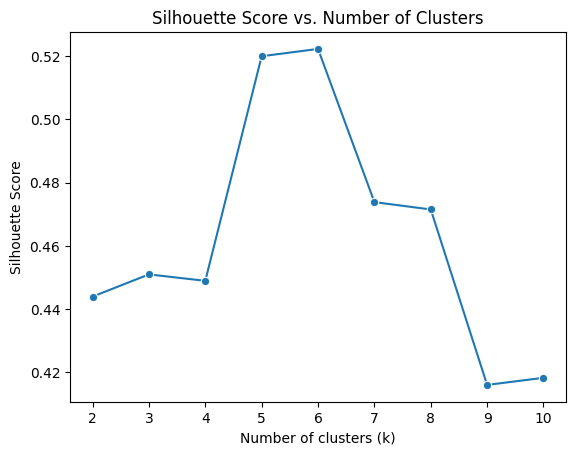

In [197]:
# Create a line plot.


# Create a line plot.
sns.lineplot(x=num_clusters, y=sil_score, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs. Number of Clusters")
plt.show()



**Question:** What does the graph show?

### Optimal k-value

To decide on an optimal k-value, fit a six-cluster model to the dataset.

In [198]:
# Fit a 6-cluster model.



# Fit a 6-cluster model.
kmeans_6 = KMeans(n_clusters=6, random_state=42, n_init='auto')
kmeans_6.fit(X_scaled)


KMeans(n_clusters=6, random_state=42)

Print out the unique labels of the fit model.

In [199]:
# Print unique labels.

# Print unique labels.
set(kmeans_6.labels_)



{np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5)}

Now, create a new column `cluster` that indicates cluster assignment in the DataFrame `penguins_subset`. It's important to understand the meaning of each cluster's labels, then decide whether the clustering makes sense.

**Note:** This task is done using `penguins_subset` because it is often easier to interpret unscaled data.

In [200]:
# Create a new column `cluster`.


# Create a new column `cluster`.
penguins_subset['cluster'] = kmeans_6.labels_



Use `groupby` to verify if any `'cluster'` can be differentiated by `'species'`.

In [201]:
# Verify if any `cluster` can be differentiated by `species`.

# Verify if any `cluster` can be differentiated by `species`.
penguins_subset.groupby(by=['cluster', 'species']).size()


cluster  species  
0        Chinstrap    32
1        Gentoo       58
2        Adelie       73
         Chinstrap     2
3        Adelie        2
         Chinstrap    34
4        Gentoo       61
5        Adelie       71
dtype: int64

Next, interpret the groupby outputs. Although the results of the groupby show that each `'cluster'` can be differentiated by `'species'`, it is useful to visualize these results. The graph shows that each `'cluster'` can be differentiated by `'species'`.

**Note:** The code for the graph below is outside the scope of this lab.

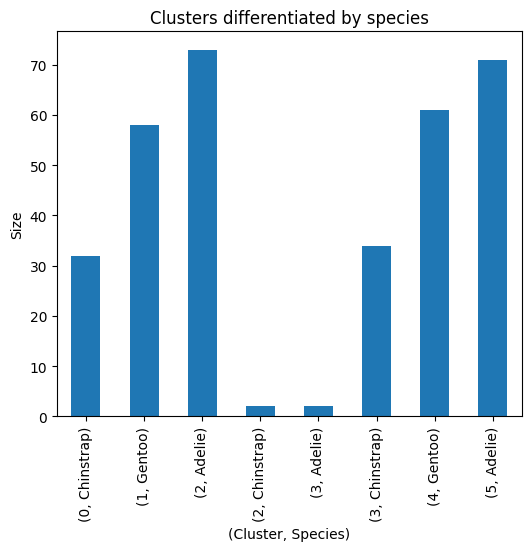

In [202]:
penguins_subset.groupby(by=['cluster', 'species']).size().plot.bar(title='Clusters differentiated by species',
                                                                   figsize=(6, 5),
                                                                   ylabel='Size',
                                                                   xlabel='(Cluster, Species)');




Use `groupby` to verify if each `'cluster'` can be differentiated by `'species'` AND `'sex_MALE'`.

In [203]:
# Verify if each `cluster` can be differentiated by `species' AND `sex_MALE`.

# Verify if each `cluster` can be differentiated by `species` AND `sex_MALE`.
penguins_subset.groupby(by=['cluster', 'species', 'sex_MALE']).size()






cluster  species    sex_MALE
0        Chinstrap  False       32
1        Gentoo     False       58
2        Adelie     False       73
         Chinstrap  False        2
3        Adelie     True         2
         Chinstrap  True        34
4        Gentoo     True        61
5        Adelie     True        71
dtype: int64

**Question:** Are the clusters differentiated by `'species'` and `'sex_MALE'`?

Finally, interpret the groupby outputs and visualize these results. The graph shows that each `'cluster'` can be differentiated by `'species'` and `'sex_MALE'`. Furthermore, each cluster is mostly comprised of one sex and one species.

**Note:** The code for the graph below is outside the scope of this lab.

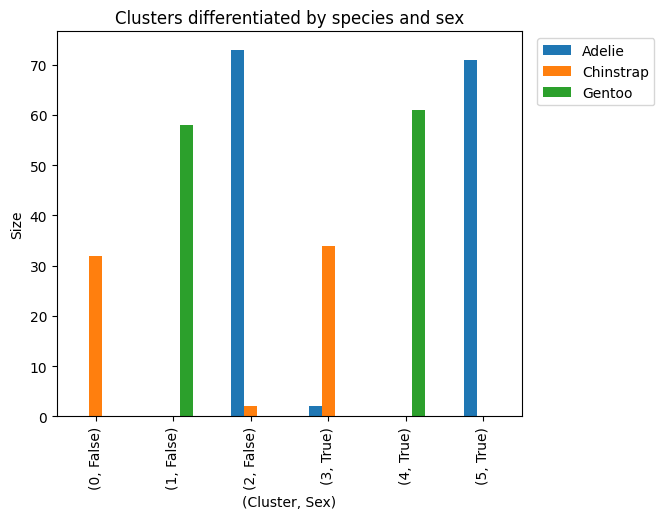

In [204]:
penguins_subset.groupby(by=['cluster','species','sex_MALE']).size().unstack(level = 'species', fill_value=0).plot.bar(title='Clusters differentiated by species and sex',
                                                                                                                      figsize=(6, 5),
                                                                                                                      ylabel='Size',
                                                                                                                      xlabel='(Cluster, Sex)')
plt.legend(bbox_to_anchor=(1.3, 1.0))

## **Considerations**


**What are some key takeaways that you learned during this lab? Consider the process you used, key tools, and the results of your investigation.**

...




**What summary would you provide to stakeholders?**

...




### References

[Gorman, Kristen B., et al. “Ecological Sexual Dimorphism and Environmental Variability within a Community of Antarctic Penguins (Genus Pygoscelis).” PLOS ONE, vol. 9, no. 3, Mar. 2014, p. e90081. PLoS Journals](https://doi.org/10.1371/journal.pone.0090081)

[Sklearn Preprocessing StandardScaler scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)